# 04 — Game theory

Notebooks 01–03 treated bidding as a single-agent estimation problem: given
a hand (and, in 03, foreseeable opponent cards), pick the bid that maximizes
your own expected score. This notebook asks the genuinely game-theoretic
question: **given that opponents are also choosing bids, what should you
do?**

The 1-card round is small enough to answer exactly, by full enumeration —
no Monte Carlo anywhere in this notebook. Implemented in
`hearts_analysis.solver`.

Regenerate the meta-game data behind §3 with:

```sh
uv run python -m hearts_analysis.experiments.metagame \
    --games 800 --seed 1 --workers 8 --out data/metagame
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hearts_analysis import cards, solver, viz

viz.use_style()
DATA = Path("../data/metagame")

## 1. Exact theory of the 1-card round

For a single card, the auction reduces to one question: is `P(my card
wins)` above or below the break-even point implied by this scoring
(`score_delta(1,1)=2`, `score_delta(1,0)=-1`, `score_delta(0,1)=-1`,
`score_delta(0,0)=1`)? Setting `E[bid 1] = E[bid 0]` gives `3p - 1 = 1 - 2p`,
i.e. **`p* = 0.4`** — independent of the table size or which card it is.

,cards bidding 1
players,
2,52
3,31
4,16
5,11
6,9
7,7


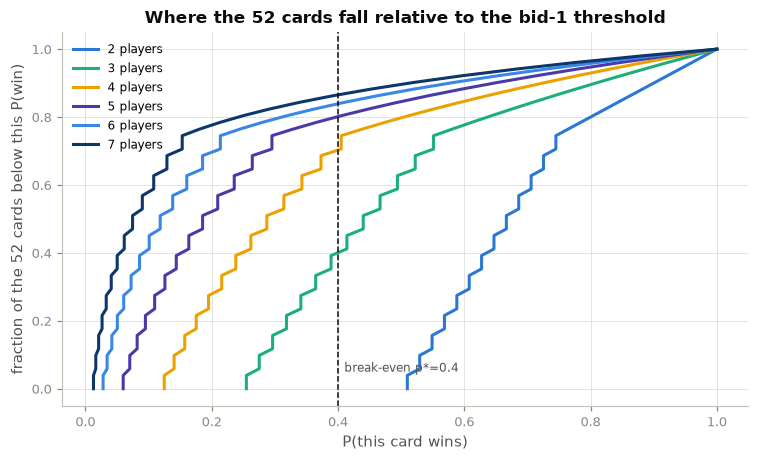

In [2]:
fig, ax = plt.subplots(figsize=(7, 4.3))
colors_6 = viz.CATEGORICAL + [viz.ORDINAL_4[1], viz.ORDINAL_4[3]]
for n, color in zip([2, 3, 4, 5, 6, 7], colors_6):
    ps = [solver.exact_p_win_one_card(c, n) for c in range(cards.NUM_CARDS)]
    ax.plot(sorted(ps), np.linspace(0, 1, 52), color=color, label=f"{n} players")
ax.axvline(0.4, color=viz.INK, linestyle="--", linewidth=1)
ax.annotate("break-even p*=0.4", (0.41, 0.05), fontsize=8, color=viz.INK_2)
ax.set_xlabel("P(this card wins)")
ax.set_ylabel("fraction of the 52 cards below this P(win)")
ax.set_title("Where the 52 cards fall relative to the bid-1 threshold")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()

table = pd.DataFrame({
    n: {"cards bidding 1": sum(solver.optimal_bid_one_card(c, n)[0] for c in range(52))}
    for n in [2, 3, 4, 5, 6, 7]
}).T
table.index.name = "players"
table

**Reading it:** as the table grows, fewer of the 52 cards clear the p*=0.4
threshold (more opponents means more chances someone beats you), so the
"correct bid-1" region shrinks — matching notebook 02 §1's finding that even
the worst card (2♣) is a correct bid-1 at 2 players but not beyond.

## 2. The 3-player round as an exact bimatrix game

With 3 players the auction has genuine multi-agent structure: bidder0 (the
dealer, who leads) and bidder1 each freely bid 0 or 1; bidder2 (last) is
then *forced* by the forbidden-bid rule to whichever bid keeps the total off
`cards_dealt=1`. `solver.three_player_bimatrix` computes the **exact**
payoff to every seat for every joint `(bid0, bid1)`, averaged over all
`52·51·50` ordered 3-card deals — no sampling.

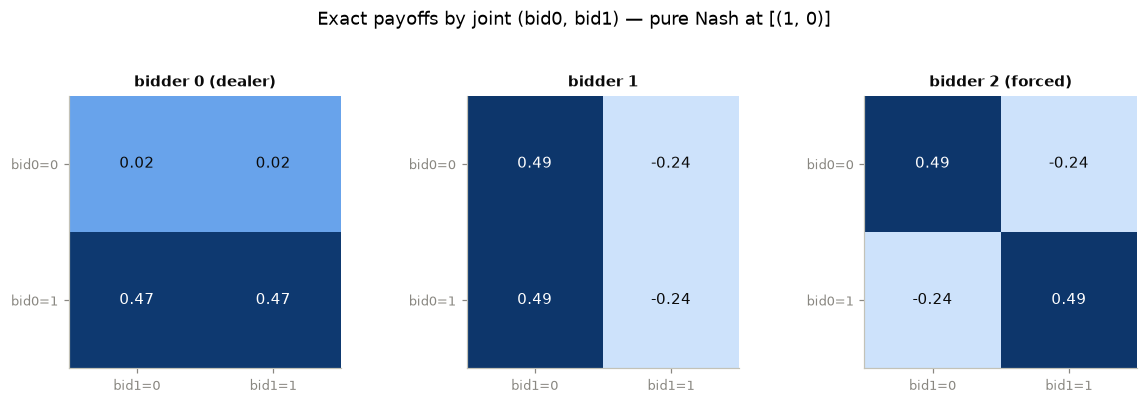

In [3]:
p0, p1, p2 = solver.three_player_bimatrix()
nash = solver.pure_nash_2x2(p0, p1)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, mat, title in zip(axes, [p0, p1, p2], ["bidder 0 (dealer)", "bidder 1", "bidder 2 (forced)"]):
    im = ax.imshow(mat, cmap=viz.SEQUENTIAL, vmin=min(p0.min(), p1.min(), p2.min()),
                    vmax=max(p0.max(), p1.max(), p2.max()))
    for i in range(2):
        for j in range(2):
            ax.annotate(f"{mat[i,j]:.2f}", (j, i), ha="center", va="center",
                        color="white" if mat[i, j] > mat.mean() else viz.INK, fontsize=10)
    ax.set_xticks([0, 1], ["bid1=0", "bid1=1"])
    ax.set_yticks([0, 1], ["bid0=0", "bid0=1"])
    ax.set_title(title, fontsize=10)
    ax.grid(False)
fig.suptitle(f"Exact payoffs by joint (bid0, bid1) — pure Nash at {nash}", y=1.05)
fig.tight_layout()

**Reading it:** bidder0's payoff is constant across bidder1's choice (and
vice versa) — in a 1-card round nobody's *score* depends on anyone else's
*bid*, only on who wins the trick, which is fixed by the cards. So each of
bidder0 and bidder1 has a **dominant strategy**, independent of the other —
the Nash equilibrium above is a dominant-strategy equilibrium, the strongest
kind. What's *not* symmetric is the two dominant strategies themselves:
bidder0 (the leader) wins far more often than bidder1, because the leader's
card **defines** the led suit — it can never be "off-suit," while bidder1's
card frequently is, and an off-suit non-trump card can never win regardless
of rank. Leading is a real structural edge, independent of card strength.

## 3. Empirical meta-game across the policy zoo

Every pairwise matchup among `{random, heuristic, mc_bidder, deck_tracker}`,
2 seats each at a 4-player table, 800 games per matchup. Cell `(row, col)` =
row policy's mean final score when playing against 2 seats of the column
policy.

,random,heuristic,mc_bidder,deck_tracker
random,-13.76,-14.02,-13.74,-14.15
heuristic,4.24,2.05,2.27,2.44
mc_bidder,3.46,2.79,2.34,2.73
deck_tracker,9.64,10.85,10.53,8.72


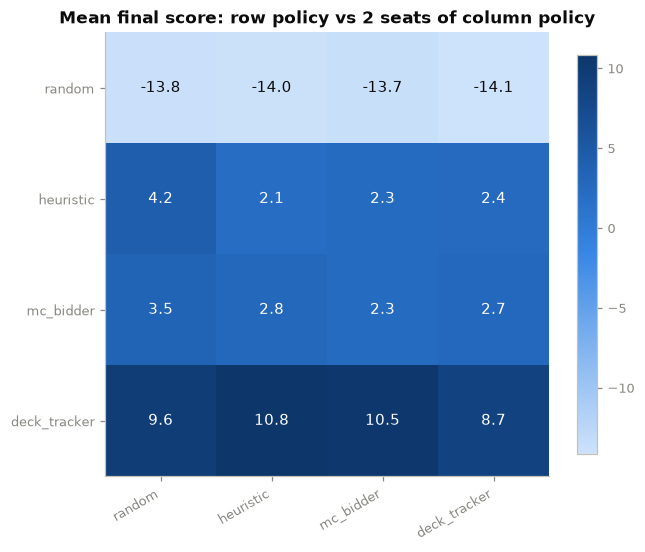

In [4]:
payoff = pd.read_parquet(DATA / "payoff_matrix.parquet")
fig, ax = plt.subplots(figsize=(6.2, 5.2))
vals = payoff.values.astype(float)
im = ax.imshow(vals, cmap=viz.SEQUENTIAL)
for i in range(len(payoff)):
    for j in range(len(payoff)):
        ax.annotate(f"{vals[i,j]:.1f}", (j, i), ha="center", va="center",
                    color="white" if vals[i, j] > np.nanmean(vals) else viz.INK, fontsize=10)
ax.set_xticks(range(len(payoff)), payoff.columns, rotation=30, ha="right")
ax.set_yticks(range(len(payoff)), payoff.index)
ax.set_title("Mean final score: row policy vs 2 seats of column policy")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.85)
fig.tight_layout()
payoff.round(2)

### Replicator dynamics: which strategy dominates the population?

Treat the payoff matrix as a symmetric meta-game and run discrete-time
replicator dynamics from a uniform start — the population share of each
policy evolves toward whatever is most fit against the current mix.

random          0.0
heuristic       0.0
mc_bidder       0.0
deck_tracker    1.0
Name: final share, dtype: float64

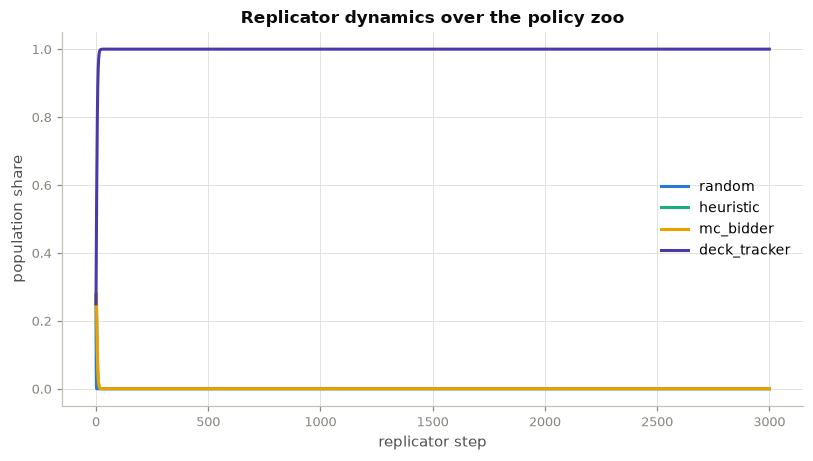

In [5]:
traj = solver.replicator_dynamics(vals, steps=3000, dt=0.05)
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for i, (name, color) in enumerate(zip(payoff.index, viz.CATEGORICAL)):
    ax.plot(traj[:, i], color=color, label=name)
ax.set_xlabel("replicator step")
ax.set_ylabel("population share")
ax.set_title("Replicator dynamics over the policy zoo")
ax.legend(fontsize=9)
fig.tight_layout()
pd.Series(traj[-1], index=payoff.index, name="final share").round(3)

**Reading it:** the trajectory shows which policies are evolutionarily
stable against this specific zoo. This is a population-level, not
individual, notion of "best" — a policy can win every one-on-one matchup and
still not be the fittest if it does poorly against itself or against the
eventual dominant strategy; read the payoff matrix's diagonal and the
dominant policy's row together to see why it wins.

## Takeaways

1. **The 1-card round has a universal break-even threshold, `p*=0.4`**,
   derived directly from the scoring rule — it doesn't depend on table size
   or the specific card, only where that card's exact win probability falls
   relative to it.
2. **Even a 3-player 1-card auction, which looks interactive, decomposes
   into independent dominant strategies** for the two free bidders — the
   forbidden-bid rule only creates interdependence for the *forced* last
   bidder, not for the players making real choices.
3. **Leading is a structural edge independent of card strength** — the
   trick leader's card always contends (it defines the led suit); every
   other seat's card only contends if it happens to match suit or is trump.
4. **The empirical meta-game and replicator dynamics** show which policy —
   from four notebooks of increasingly sophisticated bidding — actually
   dominates a population that includes all of them, closing the loop from
   `RandomPolicy` through `DeckTrackerPolicy`.

This completes the four-phase analysis: baseline statistics (01), optimal
bidding (02), the deck-tracking exploit the game's own design permits (03),
and the game-theoretic structure underneath the auction (04).